# YOLOX-Tiny: all available annotated camera data

Run notebook 07 first, then run these cells in order. The training cell starts a fresh run each time: Run All WILL prepare data and train.

Sources: every video frame from MIDV-500 and MIDV-2019 (21,000 frames), plus every downloaded MIDV-2020 photo (1,000 images). There is no frame stride. Images are resized to a maximum side of 960 for storage, and letterboxed to 416 for the model. Original datasets and previous prepared data/checkpoints are preserved.

Reuse the existing roughly 60/20/20 train/validation/test assignment by document design. MIDV-2019 shares specimens with MIDV-500; MIDV-2020's ten designs are mapped to the SAME assignment. No design crosses splits. This gives a more conservative test of unseen designs than randomly splitting 2020 photos. The existing assignment, rather than an exact frame percentage, determines final counts.

Passport booklets and driving licences are targets. Passport cards, internal passports, and other IDs are negatives. Fully out-of-frame targets are retained as negatives. Static reference/template images and duplicate original video containers are not extra camera training samples. Uploaded phone photos stay out of training because their boxes are not annotated and they serve as a separate final sanity check.

Only train updates weights; validation selects the best checkpoint and later the confidence threshold. Test is evaluated separately in notebook 09. Earlier experiments already inspected test data, so report this as a development comparison rather than a new blind benchmark.

Initial experiment: 40 epochs, batch 16, 416 pixels, pretrained YOLOX-Tiny, AdamW at 0.0002 with cosine decay. Brightness/contrast augmentation only; this is a simple baseline rather than YOLOX's full mosaic training recipe. Progress and ETA are estimates, and actual runtime is not yet measured.

Metrics: correct class and bounding-box IoU >= 0.50 for recall; negative false-positive rate is the fraction of negative images with any accepted detection. Goals: each class recall >=90%, negative false positives <=5%. Detector confidence is not capture quality.

In [1]:
from pathlib import Path
import sys
import json

PROJECT = Path("/home/joe/PycharmProjects/id-capture")
SOURCE = PROJECT / "training/vendor/YOLOX"
DATA = PROJECT / "training/data/yolox_all_sources"
WEIGHTS = PROJECT / "training/weights/yolox_tiny_coco.pth"
assert (SOURCE / "yolox").is_dir() and WEIGHTS.is_file(), "Run notebook 07 first."

for directory in (str(PROJECT), str(SOURCE)):
    if directory not in sys.path:
        sys.path.insert(0, directory)

from training.yolox_workflow import prepare_data, train_model, save_json

EPOCHS = 40
BATCH = 16
IMAGE_SIZE = 416
SEED = 42

## Prepare all three sources

This cell reads source images and annotations, writes a new derived dataset, and prints counts by source/class/split. It can reuse a completed manifest or restart an interrupted preparation with the same configuration. It never changes the existing split assignment.

In [3]:
manifest = prepare_data(
    project=PROJECT,
    source_root=Path("/home/joe/training-data"),
    output=DATA,
)
print("Prepared dataset:", DATA)
print("Total images:", len(manifest["records"]))

Available camera images: {'midv500': 15000, 'midv2019': 6000, 'midv2020': 1000}
Prepare 250/22000 | 1.1% | Elapsed 0:00:04 | Remaining 0:06:11 | Estimated finish 2026-10-21 16:30:03 BST
Prepare 500/22000 | 2.3% | Elapsed 0:00:08 | Remaining 0:06:10 | Estimated finish 2026-10-21 16:30:06 BST
Prepare 750/22000 | 3.4% | Elapsed 0:00:13 | Remaining 0:06:09 | Estimated finish 2026-10-21 16:30:10 BST
Prepare 1000/22000 | 4.5% | Elapsed 0:00:17 | Remaining 0:06:11 | Estimated finish 2026-10-21 16:30:16 BST
Prepare 1250/22000 | 5.7% | Elapsed 0:00:22 | Remaining 0:06:07 | Estimated finish 2026-10-21 16:30:17 BST
Prepare 1500/22000 | 6.8% | Elapsed 0:00:26 | Remaining 0:06:07 | Estimated finish 2026-10-21 16:30:22 BST
Prepare 1750/22000 | 8.0% | Elapsed 0:00:31 | Remaining 0:06:09 | Estimated finish 2026-10-21 16:30:28 BST
Prepare 2000/22000 | 9.1% | Elapsed 0:00:37 | Remaining 0:06:13 | Estimated finish 2026-10-21 16:30:38 BST
Prepare 2250/22000 | 10.2% | Elapsed 0:00:42 | Remaining 0:06:12 | 

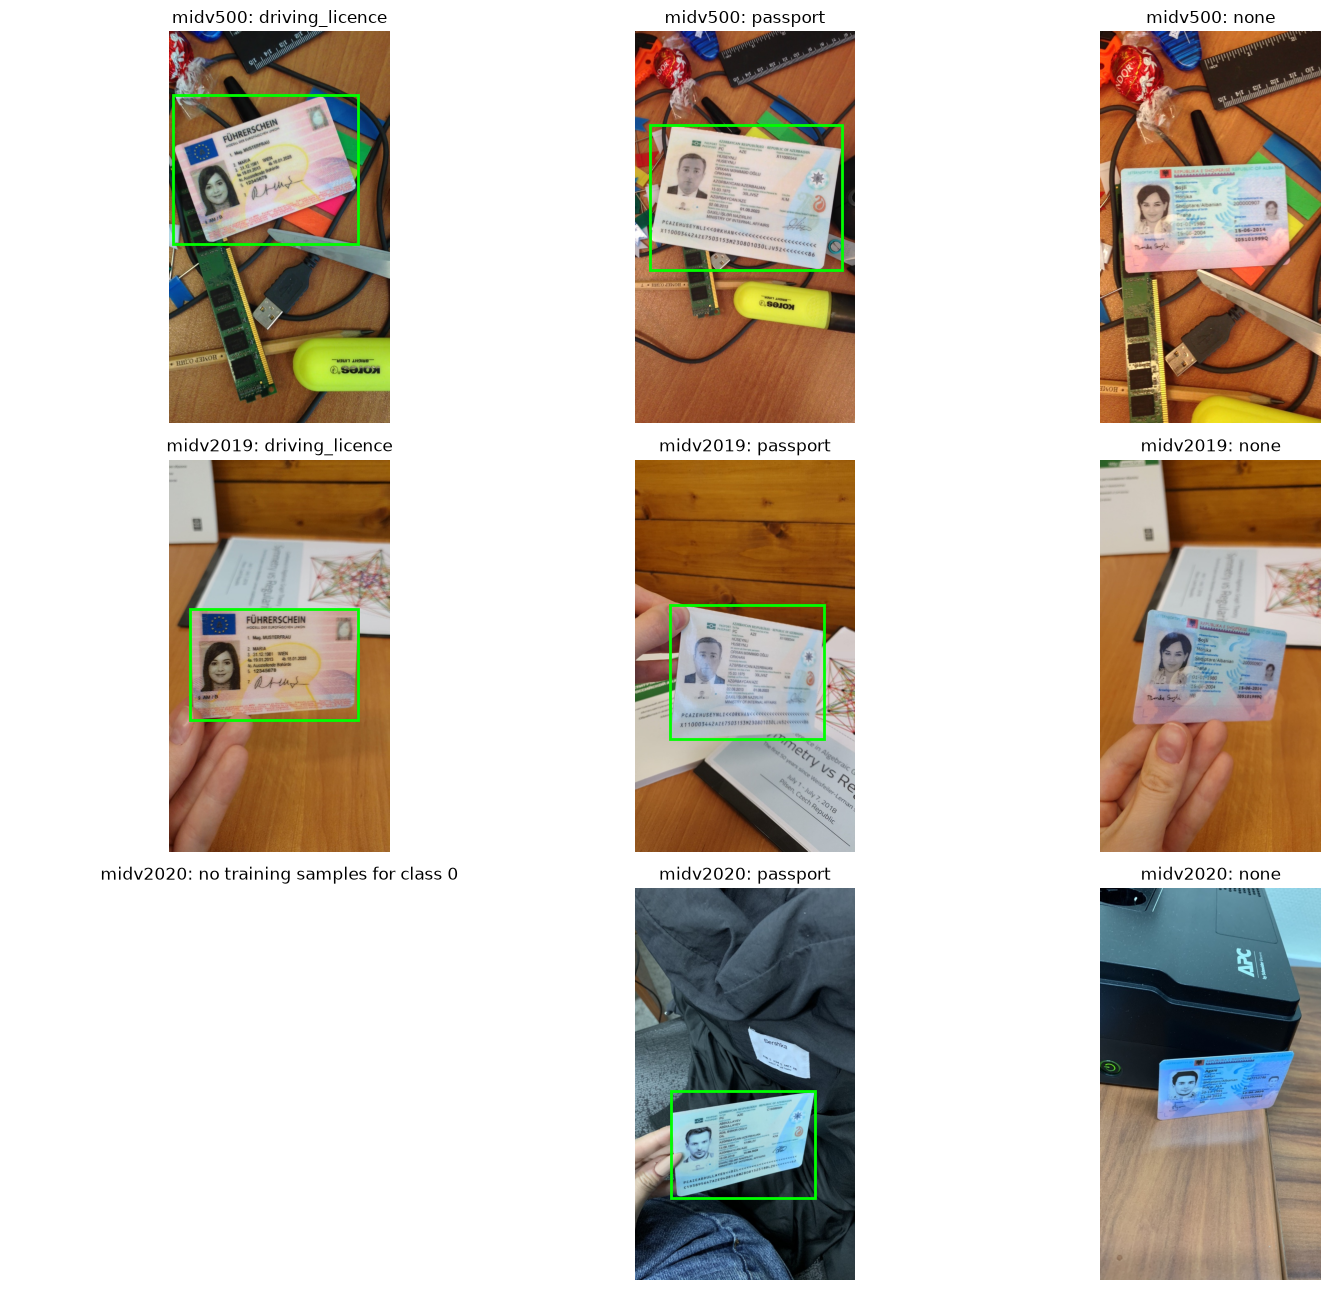

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import cv2

records = manifest["records"]
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for row, source in enumerate(("midv500", "midv2019", "midv2020")):
    for column, cls in enumerate((0, 1, None)):
        ax = axes[row, column]
        record = next((r for r in records if r["source"] == source
                       and r["split"] == "train" and r["class"] == cls), None)
        if record is None:
            ax.set_title(f"{source}: no training samples for class {cls}")
        else:
            ax.imshow(cv2.cvtColor(cv2.imread(record["image"]), cv2.COLOR_BGR2RGB))
            if record["box"] is not None:
                x1, y1, x2, y2 = record["box"]
                ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                                       fill=False, edgecolor="lime", linewidth=2))
            name = "none" if cls is None else ("driving_licence", "passport")[cls]
            ax.set_title(f"{source}: {name}")
        ax.axis("off")
plt.tight_layout()
plt.show()

## Start training

The next cell starts the full GPU run. Reduce BATCH to 8 if GPU memory is insufficient. Each run writes a separate directory, last.pth after each epoch, and best.pth selected using validation. Test images never enter the training loop. The run pointer is updated only after successful completion.

In [5]:
RUN = train_model(
    manifest=manifest,
    checkpoint=WEIGHTS,
    runs=PROJECT / "training/runs",
    epochs=EPOCHS,
    batch=BATCH,
    size=IMAGE_SIZE,
    seed=SEED,
)
save_json(DATA / "latest_run.json", {
    "run": str(RUN),
    "best": str(RUN / "best.pth"),
    "manifest": str(DATA / "manifest.json"),
    "size": IMAGE_SIZE,
})
print("Next: run notebook 09 for validation calibration and held-back testing.")

train 13100 {('midv500', 'none'): 4292, ('midv500', 'driving_licence'): 2362, ('midv500', 'passport'): 2346, ('midv2019', 'none'): 1680, ('midv2019', 'driving_licence'): 960, ('midv2019', 'passport'): 960, ('midv2020', 'none'): 200, ('midv2020', 'passport'): 300}
val 4400 {('midv500', 'none'): 1511, ('midv500', 'passport'): 890, ('midv500', 'driving_licence'): 599, ('midv2019', 'none'): 600, ('midv2019', 'passport'): 360, ('midv2019', 'driving_licence'): 240, ('midv2020', 'none'): 100, ('midv2020', 'passport'): 100}
test 4500 {('midv500', 'passport'): 884, ('midv500', 'none'): 1537, ('midv500', 'driving_licence'): 579, ('midv2019', 'passport'): 360, ('midv2019', 'driving_licence'): 240, ('midv2019', 'none'): 600, ('midv2020', 'none'): 300}
PASS: no document design crosses splits; all images exist.
Loaded pretrained tensors: 456 | New class-head tensors: 6


/home/joe/PycharmProjects/id-capture/training/vendor/YOLOX/yolox/models/yolo_head.py:474: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


Epoch 1/40, batch 50/819, loss 4.7122 | 0.1% | Elapsed 0:00:12 | Remaining 2:35:28 | Estimated finish 2026-10-21 19:19:54 BST
Epoch 1/40, batch 100/819, loss 3.5101 | 0.3% | Elapsed 0:00:22 | Remaining 2:16:13 | Estimated finish 2026-10-21 19:00:48 BST
Epoch 1/40, batch 150/819, loss 2.9727 | 0.4% | Elapsed 0:00:32 | Remaining 2:12:20 | Estimated finish 2026-10-21 18:57:05 BST
Epoch 1/40, batch 200/819, loss 2.6485 | 0.5% | Elapsed 0:00:42 | Remaining 2:07:32 | Estimated finish 2026-10-21 18:52:27 BST
Epoch 1/40, batch 250/819, loss 2.4318 | 0.7% | Elapsed 0:00:51 | Remaining 2:04:27 | Estimated finish 2026-10-21 18:49:31 BST
Epoch 1/40, batch 300/819, loss 2.2823 | 0.8% | Elapsed 0:01:01 | Remaining 2:02:23 | Estimated finish 2026-10-21 18:47:37 BST
Epoch 1/40, batch 350/819, loss 2.1577 | 1.0% | Elapsed 0:01:10 | Remaining 2:00:58 | Estimated finish 2026-10-21 18:46:21 BST
Epoch 1/40, batch 400/819, loss 2.0543 | 1.1% | Elapsed 0:01:19 | Remaining 1:59:44 | Estimated finish 2026-10-2